In [26]:
from pathlib import Path
import pandas as pd
import numpy as np
import os
import glob
import matplotlib.pyplot as plt

In [27]:
input_dir = Path("202608-citibike-tripdata")
output_dir = Path("clean-202608-citibike-tripdata")
source_files = sorted(input_dir.glob("*.csv"))

if not source_files:
    raise FileNotFoundError(f"No CSV files found in {input_dir}")

output_dir.mkdir(parents=True, exist_ok=True)
chunk_size = 250_000
totals = {"rows_before": 0, "over_3_hours": 0, "negative_duration": 0, "rows_retained": 0}

for source_file in source_files:
    output_file = output_dir / f"{source_file.stem}_cleaned.csv"
    file_totals = {"rows_before": 0, "over_3_hours": 0, "negative_duration": 0, "rows_retained": 0}

    # Process in chunks so the full set of large CSV files does not need to fit in memory.
    for chunk_number, chunk in enumerate(
        pd.read_csv(source_file, chunksize=chunk_size, low_memory=False)
    ):
        # Calculate ride duration from the recorded start and end timestamps.
        duration = pd.to_datetime(chunk["ended_at"]) - pd.to_datetime(chunk["started_at"])
        over_3_hours = duration > pd.Timedelta(hours=3)
        negative_duration = duration < pd.Timedelta(0)

        # Keep rides from zero through three hours; remove long and negative-duration rides.
        cleaned_chunk = chunk.loc[~(over_3_hours | negative_duration)]

        file_totals["rows_before"] += len(chunk)
        file_totals["over_3_hours"] += int(over_3_hours.sum())
        file_totals["negative_duration"] += int(negative_duration.sum())
        file_totals["rows_retained"] += len(cleaned_chunk)
        cleaned_chunk.to_csv(
            output_file,
            mode="w" if chunk_number == 0 else "a",
            header=chunk_number == 0,
            index=False,
        )

    for key in totals:
        totals[key] += file_totals[key]

    print(
        f"{source_file.name}: {file_totals['rows_before']:,} rows before; "
        f"{file_totals['over_3_hours']:,} over 3 hours removed; "
        f"{file_totals['negative_duration']:,} negative-duration rides removed; "
        f"{file_totals['rows_retained']:,} retained -> {output_file}"
    )

print("\nOverall cleaning summary")
print(f"Rows before cleaning: {totals['rows_before']:,}")
print(f"Columns per input file: {len(pd.read_csv(source_files[0], nrows=0).columns)}")
print(f"Were any original rides over 3 hours? {'Yes' if totals['over_3_hours'] else 'No'}")
print(f"Rides over 3 hours removed: {totals['over_3_hours']:,}")
print(f"Were any original rides negative-duration? {'Yes' if totals['negative_duration'] else 'No'}")
print(f"Rides with negative duration removed: {totals['negative_duration']:,}")
print(f"Rows retained: {totals['rows_retained']:,}")
print(f"Cleaned CSV files saved in: {output_dir}")

202608-citibike-tripdata_1.csv: 1,000,000 rows before; 791 over 3 hours removed; 0 negative-duration rides removed; 999,209 retained -> clean-202608-citibike-tripdata/202608-citibike-tripdata_1_cleaned.csv
202608-citibike-tripdata_2.csv: 1,000,000 rows before; 727 over 3 hours removed; 0 negative-duration rides removed; 999,273 retained -> clean-202608-citibike-tripdata/202608-citibike-tripdata_2_cleaned.csv
202608-citibike-tripdata_3.csv: 1,000,000 rows before; 1,904 over 3 hours removed; 0 negative-duration rides removed; 998,096 retained -> clean-202608-citibike-tripdata/202608-citibike-tripdata_3_cleaned.csv
202608-citibike-tripdata_4.csv: 1,000,000 rows before; 1,462 over 3 hours removed; 0 negative-duration rides removed; 998,538 retained -> clean-202608-citibike-tripdata/202608-citibike-tripdata_4_cleaned.csv
202608-citibike-tripdata_5.csv: 1,000,000 rows before; 961 over 3 hours removed; 0 negative-duration rides removed; 999,039 retained -> clean-202608-citibike-tripdata/20260

In [28]:
csv_files = glob.glob(os.path.join('clean-202608-citibike-tripdata', "*.csv"))

df = pd.concat([pd.read_csv(file) for file in csv_files], ignore_index=True)

print(df.shape)
df.head()

/var/folders/qd/92q86s8s6l51v7_qfzdpgvr00000gn/T/ipykernel_38205/1589914982.py:3: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.concat([pd.read_csv(file) for file in csv_files], ignore_index=True)
/var/folders/qd/92q86s8s6l51v7_qfzdpgvr00000gn/T/ipykernel_38205/1589914982.py:3: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.concat([pd.read_csv(file) for file in csv_files], ignore_index=True)
/var/folders/qd/92q86s8s6l51v7_qfzdpgvr00000gn/T/ipykernel_38205/1589914982.py:3: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.concat([pd.read_csv(file) for file in csv_files], ignore_index=True)
/var/folders/qd/92q86s8s6l51v7_qfzdpgvr00000gn/T/ipykernel_38205/1589914982.py:3: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.concat([pd.read_csv(file)

(5240216, 13)


,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual
0,E4A8132DACF670C3,electric_bike,2026-08-10 14:31:22.100,2026-08-10 14:37:37.034,E 33 St & 5 Ave,6322.01,W 24 St & 7 Ave,6257.03,40.747659,-73.984907,40.744876,-73.995299,member
1,8382768C05C30BB4,electric_bike,2026-08-10 08:04:28.348,2026-08-10 08:33:27.680,Emerson Pl & Myrtle Ave,4683.02,W 24 St & 7 Ave,6257.03,40.693631,-73.962236,40.744876,-73.995299,member
2,3A1C43832BBE4FCD,classic_bike,2026-08-08 19:36:32.350,2026-08-08 19:43:47.890,Broadway & E 19 St,5980.11,W 24 St & 7 Ave,6257.03,40.738290,-73.990060,40.744876,-73.995299,member
3,5C9BC6DFC4DEA183,electric_bike,2026-08-05 14:34:27.749,2026-08-05 14:46:23.526,Sterling Pl & Bedford Ave,3993.03,Cumberland St & Lafayette Ave,4428.02,40.672695,-73.954131,40.687534,-73.972652,member
4,355579CC64D1BE20,electric_bike,2026-08-01 14:16:44.531,2026-08-01 14:29:39.539,Sterling Pl & Bedford Ave,3993.03,Cumberland St & Lafayette Ave,4428.02,40.672695,-73.954131,40.687534,-73.972652,member


### Warm Up

1. Using the start and end times, compute each ride’s duration in minutes and plot a histogram
of ride durations.


Text(0, 0.5, 'Frequency')

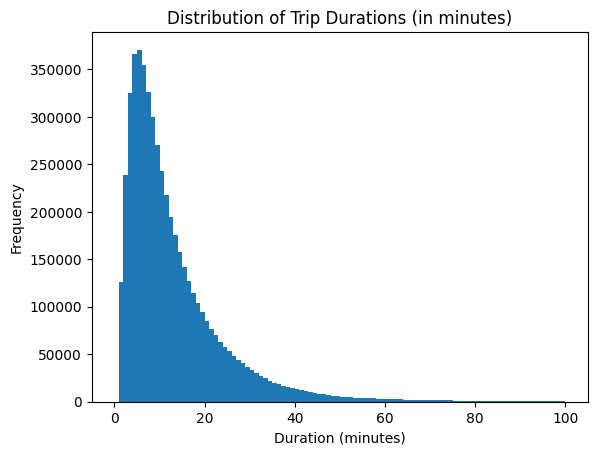

In [29]:
df['started_at'] = pd.to_datetime(df['started_at'])
df['ended_at'] = pd.to_datetime(df['ended_at'])

df['duration_min'] = (df['ended_at'] - df['started_at']).dt.total_seconds() / 60

plt.hist(df['duration_min'], bins=100, range=(0, 100))
plt.title('Distribution of Trip Durations (in minutes)')
plt.xlabel('Duration (minutes)')
plt.ylabel('Frequency')

2. What is the expected ride duration (the average ride duration)? What is the empirical variance
of ride duration? What is the probability that a ride lasts more than 20 minutes?

In [30]:
average_duration = df['duration_min'].mean()
duration_variance = df['duration_min'].var()
prob_greater_20 = df[df['duration_min'] > 20].shape[0] / df.shape[0]


print(f'Average trip duration: {average_duration} minutes')
print(f"Variance of trip durations: {duration_variance} minutes^2")
print(f"Probability of trip duration > 20 minutes: {prob_greater_20}")

Average trip duration: 13.486728892765743 minutes
Variance of trip durations: 162.87468623895418 minutes^2
Probability of trip duration > 20 minutes: 0.18912025763823476


3. What is the probability that a ride lasts more than 20 minutes conditional on the user being
a Citi Bike member?

In [31]:
citibike_member = df[df['member_casual'] == 'member']
prob_greater_20_member = citibike_member[citibike_member['duration_min'] > 20].shape[0] / citibike_member.shape[0]

print(f"Probability of trip duration > 20 minutes given citibike member: {prob_greater_20_member}")

Probability of trip duration > 20 minutes given citibike member: 0.154115787926601


4. Suppose that a ride lasts more than 25 minutes. What is the probability that this ride belongs
to a Citi Bike member?

In [32]:
ride_over_25 = df[df['duration_min'] > 25]
prob_citi_member = ride_over_25[ride_over_25['member_casual'] == 'member'].shape[0] / ride_over_25.shape[0]

print(f'Probability of being a citibike member given the trip duration > 25 minutes: {prob_citi_member}')

Probability of being a citibike member given the trip duration > 25 minutes: 0.6021240627983784


5. What is the expected ride duration of an electric bike? What is the expected ride duration of
a classic bike?

In [33]:
electric_bike_mean = df[df['rideable_type'] == 'electric_bike']['duration_min'].mean()
classic_bike_mean = df[df['rideable_type'] == 'classic_bike']['duration_min'].mean()

print(f'Average trip duration for electric bikes: {electric_bike_mean} minutes')
print(f'Average trip duration for classic bikes: {classic_bike_mean} minutes')

Average trip duration for electric bikes: 13.468248310798492 minutes
Average trip duration for classic bikes: 13.536927195731472 minutes


6. Suppose that a ride lasts less than 10 minutes. What is the probability that it uses an electric
bike? What is the probability that it uses a classic bike? Comment on the results.

In [34]:
ride_under_10 = df[df['duration_min'] < 10]
prob_classic_given_under_10 = ride_under_10[ride_under_10['rideable_type'] == 'classic_bike'].shape[0] / ride_under_10.shape[0]
prob_electric_given_under_10 = ride_under_10[ride_under_10['rideable_type'] == 'electric_bike'].shape[0] / ride_under_10.shape[0]

print(f'Probability of being a classic bike user given the trip duration < 10 minutes: {prob_classic_given_under_10}')
print(f'Probability of being an electric bike user given the trip duration < 10 minutes: {prob_electric_given_under_10}')

Probability of being a classic bike user given the trip duration < 10 minutes: 0.2795684954163652
Probability of being an electric bike user given the trip duration < 10 minutes: 0.7204315045836348


Given the trip duration is less than 10 minutes, the probability that the bike is electric is much higher than it being a classic bike, most likely becuase electric bikes are faster so it takes less time to get places.

### Part I

In [42]:
top_3_stations = (
    df['start_station_name']
    .value_counts()
    .head(20)
)

top_3_stations

start_station_name
W 21 St & 6 Ave                   17722
Pier 61 at Chelsea Piers          16739
E 17 St & Broadway                16030
7 Ave & Central Park South        15283
W 31 St & 7 Ave                   15171
Broadway & E 14 St                14858
9 Ave & W 33 St                   14470
Broadway & W 58 St                14371
University Pl & E 14 St           14144
11 Ave & W 41 St                  14121
6 Ave & W 33 St                   13837
Central Park S & 6 Ave            13524
10 Ave & W 14 St                  13499
Metropolitan Ave & Bedford Ave    13385
Broadway & W 25 St                13346
Cleveland Pl & Spring St          13226
W 4 St & 7 Ave S                  13176
Greenwich Ave & 8 Ave             13130
Carmine St & 6 Ave                12962
N 7 St & Driggs Ave               12654
Name: count, dtype: int64

In [41]:
df[df['start_station_name'] == "Broadway & E 14 St"]

,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual,duration_min
649,517E9FCBF140807D,classic_bike,2026-08-14 15:42:33.687,2026-08-14 15:53:37.624,Broadway & E 14 St,5905.12,Carmine St & 6 Ave,5763.03,40.734546,-73.990741,40.730386,-74.002150,member,11.065617
654,7F19834CBD216DCD,electric_bike,2026-08-11 18:42:45.997,2026-08-11 19:03:02.784,Broadway & E 14 St,5905.12,W 63 St & Broadway,7052.01,40.734546,-73.990741,40.771639,-73.982614,member,20.279783
1339,CBA1464AF8568960,electric_bike,2026-08-04 17:31:48.136,2026-08-04 17:44:45.854,Broadway & E 14 St,5905.12,Broadway & W 29 St,6289.06,40.734546,-73.990741,40.746201,-73.988557,member,12.961967
1873,715879AEF0496FBB,electric_bike,2026-08-13 15:56:44.693,2026-08-13 16:04:10.200,Broadway & E 14 St,5905.12,Ave D & E 8 St,5506.10,40.734546,-73.990741,40.723684,-73.975748,member,7.425117
1875,A85BA674CD77E76C,electric_bike,2026-08-07 07:32:09.668,2026-08-07 07:42:20.856,Broadway & E 14 St,5905.12,Ave D & E 8 St,5506.10,40.734546,-73.990741,40.723684,-73.975748,member,10.186467
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5233847,64B9C7EA2EEFCD19,electric_bike,2026-08-31 16:47:41.891,2026-08-31 17:06:27.410,Broadway & E 14 St,5905.12,W 47 St & 9 Ave,6786.02,40.734546,-73.990741,40.761530,-73.990070,member,18.758650
5233851,94FC7CA9F9A12E48,classic_bike,2026-08-29 18:06:43.012,2026-08-29 18:12:31.097,Broadway & E 14 St,5905.12,1 Ave & E 6 St,5626.15,40.734546,-73.990741,40.726331,-73.986169,member,5.801417
5233865,EC37E40F7BC3BCA2,classic_bike,2026-08-30 18:45:29.792,2026-08-30 18:52:36.268,Broadway & E 14 St,5905.12,1 Ave & E 6 St,5626.15,40.734546,-73.990741,40.726331,-73.986169,member,7.107933
5235951,97935FC03584023A,electric_bike,2026-08-31 15:22:46.600,2026-08-31 15:38:01.399,Broadway & E 14 St,5905.12,E 39 St & Lexington Ave,6389.09,40.734546,-73.990741,40.749499,-73.977292,member,15.246650


In [43]:
df[df['start_station_name'] == "N 7 St & Driggs Ave"]

,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual,duration_min
1028,398E324BE5BF866E,electric_bike,2026-08-14 06:31:44.435,2026-08-14 06:37:55.192,N 7 St & Driggs Ave,5340.01,N Henry St & Norman Ave,5656.03,40.716967,-73.956388,40.727700,-73.943950,member,6.179283
1323,9B1BDC5628975A13,classic_bike,2026-08-06 21:37:07.359,2026-08-06 21:43:18.995,N 7 St & Driggs Ave,5340.01,Manhattan Ave & Leonard St,5442.09,40.716967,-73.956388,40.720840,-73.948440,member,6.193933
1324,923FEA65097B8DCE,electric_bike,2026-08-04 08:37:08.011,2026-08-04 08:52:29.493,N 7 St & Driggs Ave,5340.01,Front St & Gold St,4927.04,40.716967,-73.956388,40.702240,-73.982578,member,15.358033
1325,377FE7662922C57D,electric_bike,2026-08-01 08:40:22.802,2026-08-01 08:54:37.374,N 7 St & Driggs Ave,5340.01,Front St & Gold St,4927.04,40.716967,-73.956388,40.702240,-73.982578,member,14.242867
1576,9701C08816B8B311,classic_bike,2026-08-05 17:37:14.898,2026-08-05 17:41:18.654,N 7 St & Driggs Ave,5340.01,Bedford Ave & Nassau Ave,5550.05,40.716967,-73.956388,40.723117,-73.952123,member,4.062600
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5228493,D63E125F9ADD5A62,electric_bike,2026-08-29 19:56:06.718,2026-08-29 20:14:26.725,N 7 St & Driggs Ave,5340.01,W Broadway & Spring St,5569.06,40.716967,-73.956388,40.724947,-74.001659,member,18.333450
5228822,7FF7E115292F694B,classic_bike,2026-08-29 13:36:46.391,2026-08-29 14:10:24.503,N 7 St & Driggs Ave,5340.01,Underhill Ave & Lincoln Pl,4042.08,40.716967,-73.956388,40.674012,-73.967146,casual,33.635200
5229378,5B31869C1AB21DD1,electric_bike,2026-08-31 13:30:28.222,2026-08-31 13:51:04.529,N 7 St & Driggs Ave,5340.01,Jefferson Ave & Evergreen Ave,4517.03,40.716967,-73.956388,40.689890,-73.914580,member,20.605117
5234372,86ECDFCB87767E23,classic_bike,2026-08-29 14:10:07.350,2026-08-29 14:48:35.307,N 7 St & Driggs Ave,5340.01,West Drive & Prospect Park West,3651.04,40.716967,-73.956388,40.661063,-73.979453,member,38.465950


In [44]:
df[df['start_station_name'] == "Metropolitan Ave & Bedford Ave"]

,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual,duration_min
631,C2A2B64545CB86CC,electric_bike,2026-08-09 12:12:52.126,2026-08-09 12:29:06.754,Metropolitan Ave & Bedford Ave,5308.04,Carmine St & 6 Ave,5763.03,40.715348,-73.960241,40.730386,-74.002150,member,16.243800
2106,8B0EFFDDE092996E,electric_bike,2026-08-02 21:33:19.992,2026-08-02 21:52:04.599,Metropolitan Ave & Bedford Ave,5308.04,Fulton St & Waverly Ave,4345.11,40.715348,-73.960241,40.683239,-73.965996,member,18.743450
2109,626AC2A9114B5110,electric_bike,2026-08-14 06:50:58.267,2026-08-14 06:53:05.526,Metropolitan Ave & Bedford Ave,5308.04,Driggs Ave & N 9 St,5411.08,40.715348,-73.960241,40.718170,-73.955201,member,2.120983
2405,486FB605770AC2CF,classic_bike,2026-08-03 18:16:18.992,2026-08-03 18:22:14.062,Metropolitan Ave & Bedford Ave,5308.04,Kent Ave & Division Ave,5021.05,40.715348,-73.960241,40.706564,-73.968319,member,5.917833
2406,D3FA935AD6A989D5,electric_bike,2026-08-14 19:38:16.980,2026-08-14 19:46:24.736,Metropolitan Ave & Bedford Ave,5308.04,Kent Ave & Division Ave,5021.05,40.715348,-73.960241,40.706564,-73.968319,member,8.129267
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5237435,B95F5BB91644CC93,electric_bike,2026-08-29 13:55:32.684,2026-08-29 14:36:36.170,Metropolitan Ave & Bedford Ave,5308.04,Carroll St & Columbia St,4348.07,40.715348,-73.960241,40.683046,-74.003486,casual,41.058100
5238288,DD5935EF22D34EC0,electric_bike,2026-08-29 16:51:19.183,2026-08-29 17:28:33.712,Metropolitan Ave & Bedford Ave,5308.04,Van Brunt St & Van Dyke St,4095.10,40.715348,-73.960241,40.675833,-74.014726,casual,37.242150
5238772,CC7E543422856368,electric_bike,2026-08-29 19:05:32.544,2026-08-29 19:21:58.012,Metropolitan Ave & Bedford Ave,5308.04,Bridge St & York St,4853.06,40.715348,-73.960241,40.701334,-73.984712,member,16.424467
5238785,8FA46A26EF22944F,electric_bike,2026-08-29 12:05:38.435,2026-08-29 12:19:42.298,Metropolitan Ave & Bedford Ave,5308.04,Market St & Henry St,5270.09,40.715348,-73.960241,40.713107,-73.994464,member,14.064383


In [45]:
new_df = df[df['start_station_name'].isin(["Broadway & E 14 St", "N 7 St & Driggs Ave", "Metropolitan Ave & Bedford Ave"])]
new_df

,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual,duration_min
631,C2A2B64545CB86CC,electric_bike,2026-08-09 12:12:52.126,2026-08-09 12:29:06.754,Metropolitan Ave & Bedford Ave,5308.04,Carmine St & 6 Ave,5763.03,40.715348,-73.960241,40.730386,-74.002150,member,16.243800
649,517E9FCBF140807D,classic_bike,2026-08-14 15:42:33.687,2026-08-14 15:53:37.624,Broadway & E 14 St,5905.12,Carmine St & 6 Ave,5763.03,40.734546,-73.990741,40.730386,-74.002150,member,11.065617
654,7F19834CBD216DCD,electric_bike,2026-08-11 18:42:45.997,2026-08-11 19:03:02.784,Broadway & E 14 St,5905.12,W 63 St & Broadway,7052.01,40.734546,-73.990741,40.771639,-73.982614,member,20.279783
1028,398E324BE5BF866E,electric_bike,2026-08-14 06:31:44.435,2026-08-14 06:37:55.192,N 7 St & Driggs Ave,5340.01,N Henry St & Norman Ave,5656.03,40.716967,-73.956388,40.727700,-73.943950,member,6.179283
1323,9B1BDC5628975A13,classic_bike,2026-08-06 21:37:07.359,2026-08-06 21:43:18.995,N 7 St & Driggs Ave,5340.01,Manhattan Ave & Leonard St,5442.09,40.716967,-73.956388,40.720840,-73.948440,member,6.193933
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5237435,B95F5BB91644CC93,electric_bike,2026-08-29 13:55:32.684,2026-08-29 14:36:36.170,Metropolitan Ave & Bedford Ave,5308.04,Carroll St & Columbia St,4348.07,40.715348,-73.960241,40.683046,-74.003486,casual,41.058100
5238288,DD5935EF22D34EC0,electric_bike,2026-08-29 16:51:19.183,2026-08-29 17:28:33.712,Metropolitan Ave & Bedford Ave,5308.04,Van Brunt St & Van Dyke St,4095.10,40.715348,-73.960241,40.675833,-74.014726,casual,37.242150
5238772,CC7E543422856368,electric_bike,2026-08-29 19:05:32.544,2026-08-29 19:21:58.012,Metropolitan Ave & Bedford Ave,5308.04,Bridge St & York St,4853.06,40.715348,-73.960241,40.701334,-73.984712,member,16.424467
5238785,8FA46A26EF22944F,electric_bike,2026-08-29 12:05:38.435,2026-08-29 12:19:42.298,Metropolitan Ave & Bedford Ave,5308.04,Market St & Henry St,5270.09,40.715348,-73.960241,40.713107,-73.994464,member,14.064383
